## Import Libraries

In [37]:
import numpy as np
from numpy.linalg import inv
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings('ignore')


In [26]:
class LinUCB:
  def __init__(self, d, n, alpha):
    if d <=0 or n <=0:
      raise ValueError('Number of featues and arms must be > 0')

    self.A_a = [np.eye(d) for _ in range(n)]
    self.b_a = [np.zeros((1,d)) for _ in range(n)]
    self.theta_hat_a = [np.zeros((d,1)) for _ in range(n)]
    self.alpha = alpha
    self.d = d
    self.n = n

  def receive_reward(self, context, arm, reward):
    self.receive_rewards([context], [arm], [reward])

  def receive_rewards(self, contexts,arms, rewards):
    if len(contexts) != len(arms) or len(contexts) != len(rewards):
      raise ValueError('Must give the same number of contexts, arms, and rewards')

    for i in range(len(contexts)):
      if len(contexts[i]) != self.d:
        raise ValueError('Context does not have the same dimentions as given in the constructor')

      x = np.array(contexts[i]).reshape((-1,1))
      x_t = x.transpose()

      xMultx_t = np.dot(x, x_t)
      contextMultipliedWithReward = np.multiply(contexts[i], rewards[i])

      cur_arm = arms[i]
      self.A_a[cur_arm] += xMultx_t
      self.b_a[cur_arm] += contextMultipliedWithReward.reshape((1,-1))

      self.theta_hat_a[cur_arm] = np.dot(inv(self.A_a[cur_arm]), self.b_a[cur_arm].transpose())

  def get_payoffs(self, context):
    if len(context) != self.d:
      raise ValueError('Context does not have the same dimentions as given in the constructor')

    payoffs = np.zeros(self.n)

    x = np.array(context).reshape((-1,1))
    x_t = x.transpose()

    for i in range(self.n):
      firstProduct = np.dot(self.theta_hat_a[i].transpose(), x)
      secondProduct = np.dot(np.dot(x_t, inv(self.A_a[i])), x)

      secondElementSqTImesAlpha = self.alpha * np.sqrt(np.abs(secondProduct))
      payoffs[i] = firstProduct + secondElementSqTImesAlpha

    return payoffs

  def choose_arm(self, context):
    payoffs = self.get_payoffs(context)

    # np.argmax(payoffs)
    max_payoff = float('-inf')
    viable_arms = []

    for i in range(self.n):
      if payoffs[i] > max_payoff:
        viable_arms = [i]
        max_payoff = payoffs[i]
      elif payoffs[i] == max_payoff:
        viable_arms.append(i)

    if not viable_arms:
      raise RuntimeError('No viable arm!')
    elif len(viable_arms) == 1:
      return viable_arms[0]
    else:
      return np.random.choice(viable_arms)

In [27]:
# Create an instance

linucb = LinUCB(d= 5, n=3, alpha = 0.1)

user_contexts = [
    np.array([1.2, 0.8, 0.5, 0.3, 0.2]),
    np.array([0.9, 1.0, 0.3, 0.5, 0.8]),
    np.array([0.5, 0.3, 0.9, 1.0, 0.7])
]

arms_selected = [linucb.choose_arm(context) for context in user_contexts]

rewards = [2.3,1.8, 2.5]

linucb.receive_rewards(user_contexts, arms_selected, rewards)

new_user_context = np.array([0.2, 1.0, 0.4, 0.9, 0.9])

payoffs = linucb.get_payoffs(new_user_context)

print('Payoffs for each arm', payoffs)

chosen_arm = linucb.choose_arm(new_user_context)

print('Chosen Arm', chosen_arm)

Payoffs for each arm [1.8314079  0.16792856 1.2646385 ]
Chosen Arm 0


<ipython-input-26-42c101b8f112>:50: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  payoffs[i] = firstProduct + secondElementSqTImesAlpha


In [28]:
# e-greedy agent

class EGreedyAgent:
  def __init__(self, n_arms, epsilon):
    self.n_arms = n_arms
    self.epsilon = epsilon
    self.q_values = np.zeros(self.n_arms)
    self.action_counts = np.zeros(self.n_arms)


  def choose_arm(self):
    if np.random.rand() < self.epsilon:
      selected_arm = np.random.choice(self.n_arms)
    else:
      selected_arm = np.argmax(self.q_values)

    return selected_arm

  def update_q_values(self, arm, reward):
    self.action_counts[arm] +=1
    self.q_values[arm] += (reward - self.q_values[arm]) / self.action_counts[arm]

In [29]:
# Simulation of product recommendation with LinUCB agent

def simulate_linucb_agent(agent, contexts, rounds):
  cumulative_rewards = []

  for _ in range(rounds):
    user_context = np.random.rand(5) # generate a random user context
    linucb_arm = agent.choose_arm(user_context)

    # get reward
    reward = np.random.normal(loc=3.0, scale= 1.0)

    # update the theta_hat
    agent.receive_reward(user_context, linucb_arm, reward)

    cumulative_rewards.append(cumulative_rewards[-1] + reward if cumulative_rewards else reward)

  return cumulative_rewards


def simulate_egreedy_agent(agent, rounds):
  cumulative_rewards = []

  for _ in range(rounds):
    user_contexts = np.random.rand(5)
    e_greedy_arm = agent.choose_arm()

    reward = np.random.normal(loc=3.0, scale = 1.0)

    # update the q_values
    agent.update_q_values(e_greedy_arm, reward)

    cumulative_rewards.append(cumulative_rewards[-1] + reward if cumulative_rewards else reward)

  return cumulative_rewards

<ipython-input-26-42c101b8f112>:50: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  payoffs[i] = firstProduct + secondElementSqTImesAlpha


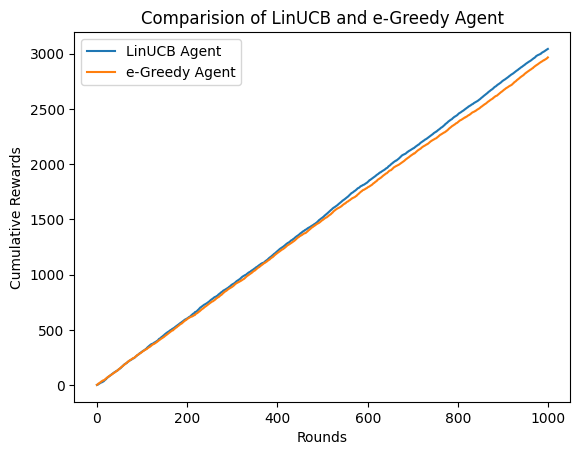

In [30]:
linucb_agent = LinUCB(d=5, n = 5, alpha= 0.1)
e_greedy_agent = EGreedyAgent(n_arms= 5, epsilon= 0.3)

rounds = 1000
np.random.seed(42)
linucb_cumulative_rewards = simulate_linucb_agent(linucb_agent, user_contexts, rounds= rounds)
e_greedy_cumulative_rewards = simulate_egreedy_agent(e_greedy_agent, rounds)


# Visualize
plt.plot(linucb_cumulative_rewards, label = 'LinUCB Agent')
plt.plot(e_greedy_cumulative_rewards, label = 'e-Greedy Agent')
plt.xlabel('Rounds')
plt.ylabel('Cumulative Rewards')
plt.legend()
plt.title('Comparision of LinUCB and e-Greedy Agent')
plt.show()


## Contextual Bandit Problems

Link to the data: https://www.kaggle.com/competitions/avazu-ctr-prediction/data

In [31]:
ctr_data = pd.read_csv('balanced_data_short.csv')
ctr_data.head()

,C14,C15,C16,C18,C19,C21,dayofweek,hour_time,selected_arm,CTR_Label
0,0.906190,0.128713,0.449393,1.000000,0.570634,0.231092,0.166667,0.826087,2,1
1,0.932467,0.128713,0.449393,0.000000,0.076752,0.399160,0.833333,0.695652,2,0
2,0.962341,0.128713,0.014170,0.000000,0.074527,0.873950,0.500000,0.434783,0,0
3,0.905260,0.128713,0.014170,0.000000,0.001112,0.605042,0.333333,0.565217,0,0
4,0.906106,0.128713,0.014170,0.666667,0.143493,0.163866,0.333333,1.000000,0,0


In [32]:
# split the data
train_data, test_data = train_test_split(ctr_data, test_size= 0.2, random_state= 42)

# print the shape of the datasets
print("Train Data Shape", train_data.shape)
print('Test Data Shape', test_data.shape)

Train Data Shape (1200, 10)
Test Data Shape (300, 10)


## LinUCB algorithm: Accuracy Performance Analysis

In [38]:


# Extract features, selected arms, and rewards
train_features = train_data[['C14', 'C15','C16','C18','C19','C21','dayofweek','hour_time']].values
train_arms = train_data['selected_arm'].values
train_rewards = train_data['CTR_Label'].values

# Initialize LinUCB with the appropriate dimentions
linucb = LinUCB(d = train_features.shape[1], n= max(train_arms)+1, alpha= 0.1)

# Train the LinUC with historical data (train_data)
for i in range(len(train_features)):
  linucb.receive_reward(train_features[i], train_arms[i], train_rewards[i])

# Test the performance of LinUCB on the test data
correct_predictions_linucb = 0

for i in range(len(test_data)):
  test_features = test_data[['C14', 'C15','C16','C18','C19','C21','dayofweek','hour_time']].iloc[i].values
  true_arm = test_data['selected_arm'].iloc[i]
  true_reward = test_data['CTR_Label'].iloc[i]

  predicted_arm = linucb.choose_arm(test_features)

  if predicted_arm == true_arm:
    correct_predictions_linucb +=1

accuracy_linucb = correct_predictions_linucb / len(test_data)

print('Accuracy of LinUCB on the test set: ', accuracy_linucb)




Accuracy of LinUCB on the test set:  0.21333333333333335


In [39]:
egreedy_features = train_data[['C14', 'C15','C16','C18','C19','C21','dayofweek','hour_time']].values
egreedy_rewards = train_data['CTR_Label'].values

egreedy = EGreedyAgent(n_arms = max(train_arms) + 1, epsilon = 0.1)


# Train egreedy agent

for i in range(len(egreedy_features)):
  chosen_arm = egreedy.choose_arm()
  reward = egreedy_rewards[i]
  egreedy.update_q_values(chosen_arm, reward)


# Evaluation of the Egreedy based on accuracy metric

correct_predictions_egreedy = 0

for i in range(len(test_data)):
  true_arm = test_data['selected_arm'].iloc[i]
  true_reward = test_data['CTR_Label'].iloc[i]

  predicted_arm  = egreedy.choose_arm()

  if predicted_arm == true_arm:
    correct_predictions_egreedy += 1


accuracy_egreedy = correct_predictions_egreedy / len(test_data)

print('Accuracy of e-greedy on the test set: ', accuracy_egreedy)

Accuracy of e-greedy on the test set:  0.35333333333333333


## Evaluation of the performance of LinUCB and e-Greedy based on Accumulated Reward

In [40]:
accumulated_rewards_linucb_test = []
accumulated_reward_egreedy_test = []

# Test the performance of LinUCB

total_reward_linucb_test = 0

for i in range(len(test_data)):
  test_features = test_data[['C14', 'C15','C16','C18','C19','C21','dayofweek','hour_time']].iloc[i].values

  predicted_arm = linucb.choose_arm(test_features)

  predicted_reward = linucb.get_payoffs(test_features)[predicted_arm]

  total_reward_linucb_test += predicted_reward
  accumulated_rewards_linucb_test.append(total_reward_linucb_test)


# test the perfrormance of e-Greedy

total_reward_egreedy_test = 0
for i in range(len(test_data)):
  predicted_arm = egreedy.choose_arm()
  predicted_reward = egreedy.q_values[predicted_arm]

  total_reward_egreedy_test += predicted_reward
  accumulated_reward_egreedy_test.append(total_reward_egreedy_test)

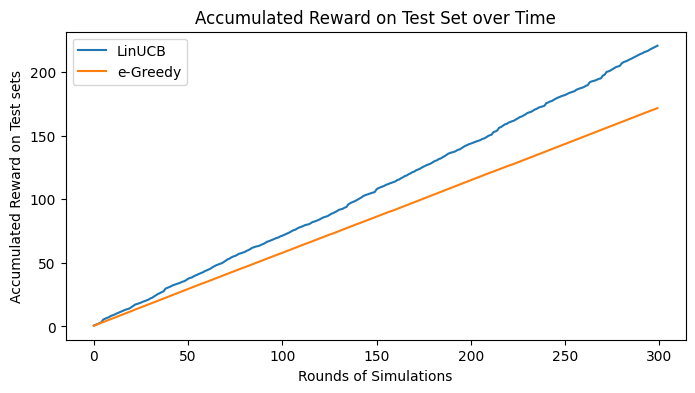

In [41]:
# Visualize the performances

plt.figure(figsize = (8,4))
plt.plot(accumulated_rewards_linucb_test, label = 'LinUCB')
plt.plot(accumulated_reward_egreedy_test, label = 'e-Greedy')
plt.xlabel('Rounds of Simulations')
plt.ylabel('Accumulated Reward on Test sets')
plt.legend()
plt.title('Accumulated Reward on Test Set over Time')
plt.show()